# Лабораторная работа 3. Кластеризация клиентов банка

**Студент:** Зоркольцев Илья Алексеевич, гр. АВТ-313

**Цель:** изучить алгоритмы кластеризации, освоить оценку качества разбиения и интерпретацию результатов.

**Датасет:** Bank Customer Segmentation (Kaggle, `bank_transactions.csv`).

**Методы:** K-means и иерархическая кластеризация (Ward).

Перед каждой ячейкой кода описано, что она делает, после неё описано, что должно получиться и как это читать. Места, помеченные ✏️, нужно заполнить своими числами и выводами после запуска.

### Что делает ячейка
Подключает библиотеки (`pandas`, `numpy`, `scikit-learn`, `matplotlib`, `seaborn`, `scipy`), фиксирует `random_state = 42` для воспроизводимости и определяет функцию `save`, которая сохраняет график в папку `figures/` и показывает его в ноутбуке.

In [15]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score,
                             adjusted_rand_score, rand_score,
                             fowlkes_mallows_score, confusion_matrix)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RS = 42
np.random.seed(RS)
OUT = "figures"
os.makedirs(OUT, exist_ok=True)


def save(name):
    plt.tight_layout()
    plt.savefig(f"{OUT}/{name}.png", dpi=150)
    plt.show()

### Что получилось
Вывода нет. Среда настроена: все случайные операции (выборки, инициализация K-means) воспроизводимы, графики будут сохраняться в `figures/`.

## 1. Загрузка и дескриптивный анализ

### Что делает ячейка
Загружает датасет Bank Customer Segmentation, выводит **размерность**, **типы признаков** и **число пропусков** по столбцам. Затем удаляет строки с пропусками в ключевых полях (дата рождения, пол, баланс) и записи с некорректным значением пола.

In [16]:
PATH = "bank_transactions.csv"          # <-- путь к файлу с Kaggle
raw = pd.read_csv(PATH)
print("Размерность (транзакции):", raw.shape)
print(raw.dtypes)
print("Пропуски:\n", raw.isna().sum())

raw = raw.dropna(subset=["CustomerDOB", "CustGender", "CustAccountBalance"])
raw = raw[raw["CustGender"].isin(["M", "F"])]

Размерность (транзакции): (1048567, 9)
TransactionID                  str
CustomerID                     str
CustomerDOB                    str
CustGender                     str
CustLocation                   str
CustAccountBalance         float64
TransactionDate                str
TransactionTime              int64
TransactionAmount (INR)    float64
dtype: object
Пропуски:
 TransactionID                 0
CustomerID                    0
CustomerDOB                3397
CustGender                 1100
CustLocation                151
CustAccountBalance         2369
TransactionDate               0
TransactionTime               0
TransactionAmount (INR)       0
dtype: int64


### Что получилось
Выведены размерность (транзакций около 1 млн, 9 столбцов), типы (даты и время хранятся как строки `object`, поэтому дальше нужен их разбор; числовые поля `CustAccountBalance` и `TransactionAmount (INR)` имеют тип `float64`) и число пропусков. Пропусков немного по сравнению с объёмом данных, поэтому удаление таких строк не искажает выборку.

✏️ **Впишите свои числа и вывод:** _..._

### Что делает ячейка
Переводит даты из строк `dd/mm/yy` в формат `datetime`. Из-за двузначного года дата рождения вроде «01/01/57» читается как 2057 год, поэтому такие даты сдвигаются на 100 лет назад. Затем вычисляется **возраст на момент транзакции** и отбрасываются записи с возрастом вне диапазона 18–90 лет (ошибки ввода).

In [17]:
# Даты: формат dd/mm/yy, двузначный год может быть истолкован как 20xx
raw["dob"] = pd.to_datetime(raw["CustomerDOB"], format="%d/%m/%y", errors="coerce")
raw["tdate"] = pd.to_datetime(raw["TransactionDate"], format="%d/%m/%y", errors="coerce")
raw = raw.dropna(subset=["dob", "tdate"])
raw.loc[raw["dob"].dt.year > 2016, "dob"] -= pd.DateOffset(years=100)
raw["age"] = (raw["tdate"] - raw["dob"]).dt.days / 365.25
raw = raw[(raw["age"] >= 18) & (raw["age"] <= 90)]
print("После очистки:", raw.shape)

После очистки: (983514, 12)


### Что получилось
Появился признак `age`, нереалистичные записи удалены. Выведено число строк после очистки: сравните его с исходным, потеряна лишь небольшая доля данных.

✏️ **Впишите свои числа и вывод:** _..._

## 2. Агрегация до уровня клиента

### Что делает ячейка
Исходные данные описывают **транзакции**, а кластеризовать нужно **клиентов**. Группируем по `CustomerID` и строим признаки: возраст, пол (`is_male`), баланс на последнюю транзакцию, число транзакций, суммарная, средняя и максимальная сумма транзакции. Выводится размерность и `describe()`.

In [18]:
raw = raw.sort_values("tdate")
g = raw.groupby("CustomerID")
df = pd.DataFrame({
    "age": g["age"].last(),
    "is_male": g["CustGender"].agg(lambda s: int(s.iloc[-1] == "M")),
    "balance": g["CustAccountBalance"].last(),
    "n_trans": g.size(),
    "total_amount": g["TransactionAmount (INR)"].sum(),
    "mean_amount": g["TransactionAmount (INR)"].mean(),
    "max_amount": g["TransactionAmount (INR)"].max(),
}).reset_index(drop=True)
print("\nРазмерность (клиенты):", df.shape)
print(df.describe().T)
print("Пропуски:", df.isna().sum().sum())

num_cols = ["age", "balance", "n_trans", "total_amount", "mean_amount", "max_amount"]


Размерность (клиенты): (837793, 7)
                 count           mean            std        min          25%  \
age           837793.0      31.212430       8.724418  18.001369    25.314168   
is_male       837793.0       0.723167       0.447434   0.000000     0.000000   
balance       837793.0  106543.477986  837289.217024   0.000000  4624.000000   
n_trans       837793.0       1.173934       0.434621   1.000000     1.000000   
total_amount  837793.0    1704.821065    6689.134260   0.000000   198.000000   
mean_amount   837793.0    1453.556536    6049.257908   0.000000   180.000000   
max_amount    837793.0    1636.355543    6629.371105   0.000000   195.000000   

                       50%          75%           max  
age              28.969199     34.55989  8.981793e+01  
is_male           1.000000      1.00000  1.000000e+00  
balance       16060.110000  53937.32000  1.150355e+08  
n_trans           1.000000      1.00000  6.000000e+00  
total_amount    500.000000   1417.00000  1.

### Что получилось
Получена таблица «один клиент = одна строка» с 7 числовыми признаками, пропусков нет. Обратите внимание на разницу между средним и медианой у `balance`, `total_amount` и `mean_amount`: если среднее многократно больше медианы, распределение имеет тяжёлый правый хвост (небольшая группа очень состоятельных или активных клиентов).

✏️ **Впишите свои числа и вывод:** _..._

## 3. Распределения, асимметрия, выбросы

### Что делает ячейка
Строит гистограммы с оценкой плотности (KDE) для шести числовых признаков. В заголовке указана **асимметрия (skew)**: при |skew| > 1 распределение сильно скошено и далеко от нормального.

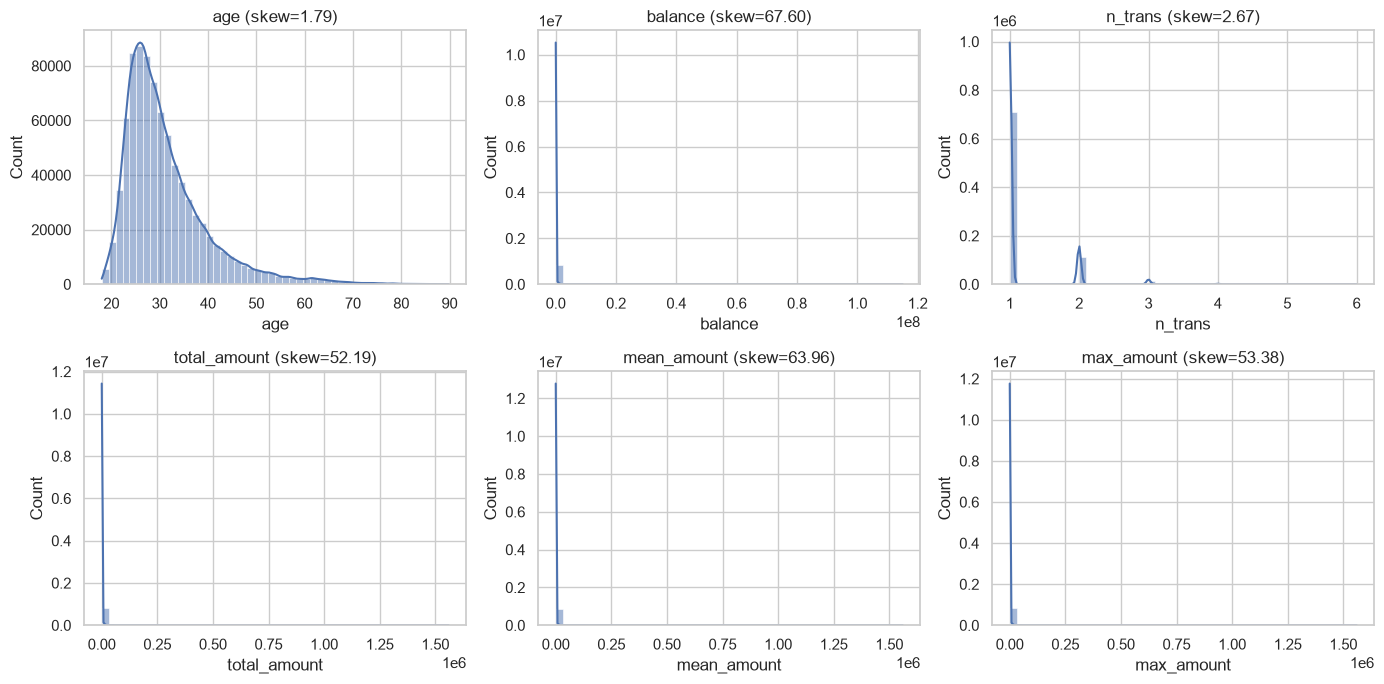

In [19]:
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for a, c in zip(ax.ravel(), num_cols):
    sns.histplot(df[c], bins=50, kde=True, ax=a)
    a.set_title(f"{c} (skew={df[c].skew():.2f})")
save("01_hist_raw")

### Что получилось
Ожидаемая картина: `age` ближе всего к нормальному распределению (с небольшим правым хвостом), а `balance`, `total_amount`, `mean_amount`, `max_amount` резко скошены вправо (основная масса у нуля, длинный хвост). `n_trans` дискретен, у большинства клиентов одна-две транзакции. Вывод: данные не нормальны, и для расстояний в K-means и Ward нужно преобразование.

✏️ **Впишите свои числа и вывод:** _..._

### Что делает ячейка
Считает долю выбросов по правилу **1.5·IQR** (значения вне [Q1 − 1.5·IQR; Q3 + 1.5·IQR]) для каждого признака.

In [20]:
def iqr_share(s):
    q1, q3 = s.quantile([.25, .75])
    i = q3 - q1
    return ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).mean()

print("\nДоля выбросов по правилу 1.5*IQR:")
print({c: round(iqr_share(df[c]), 3) for c in num_cols})


Доля выбросов по правилу 1.5*IQR:
{'age': np.float64(0.05), 'balance': np.float64(0.133), 'n_trans': np.float64(0.153), 'total_amount': np.float64(0.102), 'mean_amount': np.float64(0.104), 'max_amount': np.float64(0.106)}


### Что получилось
Выведен словарь «признак → доля выбросов». У скошенных признаков доля выбросов заметно выше, чем у `age`. Выбросы **не удаляются**: это реальные клиенты (крупные балансы, активные пользователи), и удаление уничтожило бы целый сегмент. Вместо этого далее применяется логарифмирование и винсоризация.

✏️ **Впишите свои числа и вывод:** _..._

## 4. Предобработка данных

### Что делает ячейка
1. Находит признаки с |skew| > 1 и применяет к ним `log1p` (сжимает правый хвост, сохраняет ноль).
2. **Винсоризация** на уровне 1% и 99%: экстремальные значения заменяются на граничные, а не удаляются.

**Обоснование:** K-means и Ward используют евклидову метрику и чувствительны и к масштабу, и к выбросам; `StandardScaler` (применяется ниже) тоже чувствителен к выбросам, поэтому хвосты нужно смягчить заранее.

In [21]:
skewed = [c for c in num_cols if abs(df[c].skew()) > 1]
print("\nЛог-преобразование:", skewed)
X_df = df.copy()
for c in skewed:
    X_df[c] = np.log1p(X_df[c].clip(lower=0))
for c in num_cols:                              # винсоризация 1% / 99%
    lo, hi = X_df[c].quantile([.01, .99])
    X_df[c] = X_df[c].clip(lo, hi)


Лог-преобразование: ['age', 'balance', 'n_trans', 'total_amount', 'mean_amount', 'max_amount']


### Что получилось
Выведен список логарифмированных признаков. Данные в `X_df` стали менее скошенными, а выбросы ограничены.

✏️ **Впишите свои числа и вывод:** _..._

### Что делает ячейка
Повторно строит гистограммы, теперь для преобразованных признаков, чтобы проверить эффект логарифмирования и винсоризации.

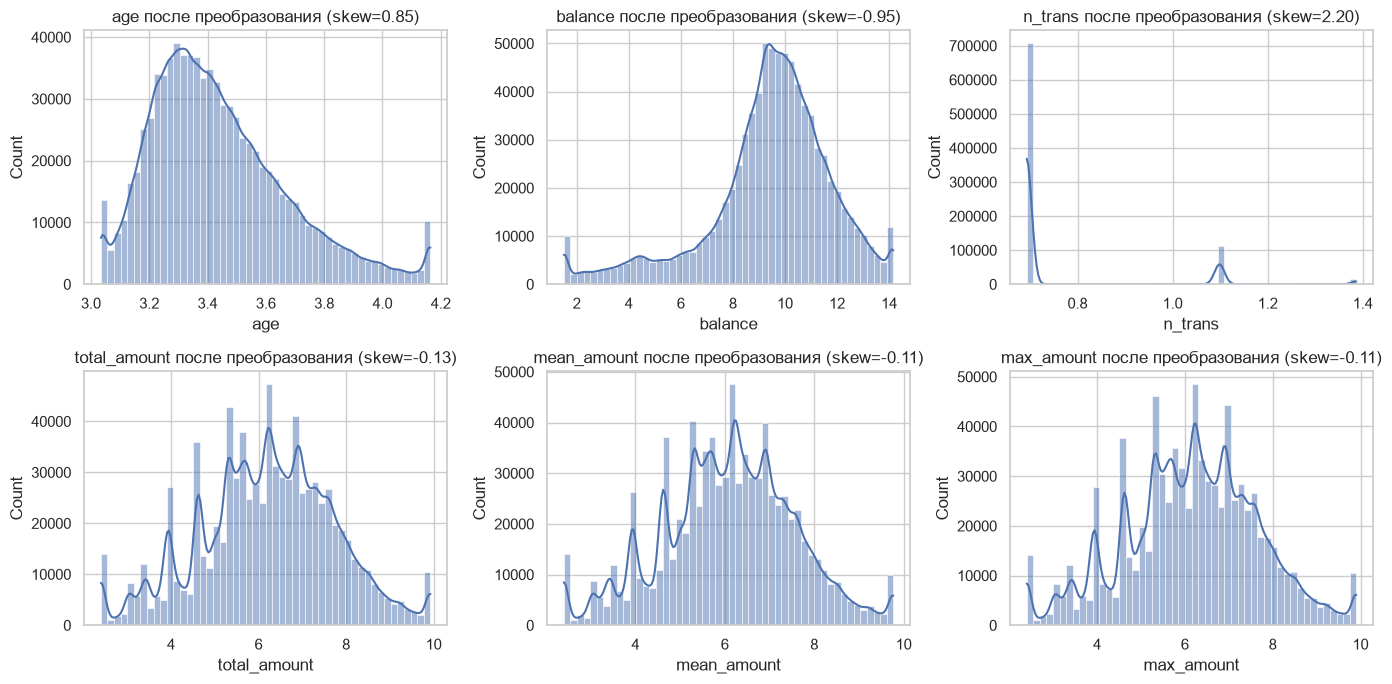

In [22]:
fig, ax = plt.subplots(2, 3, figsize=(14, 7))
for a, c in zip(ax.ravel(), num_cols):
    sns.histplot(X_df[c], bins=50, kde=True, ax=a)
    a.set_title(f"{c} после преобразования (skew={X_df[c].skew():.2f})")
save("02_hist_transformed")

### Что получилось
Хвосты стали заметно короче, значения |skew| приблизились к нулю, формы распределений стали ближе к колоколообразным. У `n_trans` остаётся дискретность. Сравните с рис. 01 и укажите, как изменился skew.

✏️ **Впишите свои числа и вывод:** _..._

## 5. Информативность признаков и кластеризуемость

### Что делает ячейка
Строит **матрицу корреляций** признаков, чтобы найти дублирующие друг друга (мультиколлинеарные) признаки. Они завышают вес одного и того же фактора при расчёте расстояний.

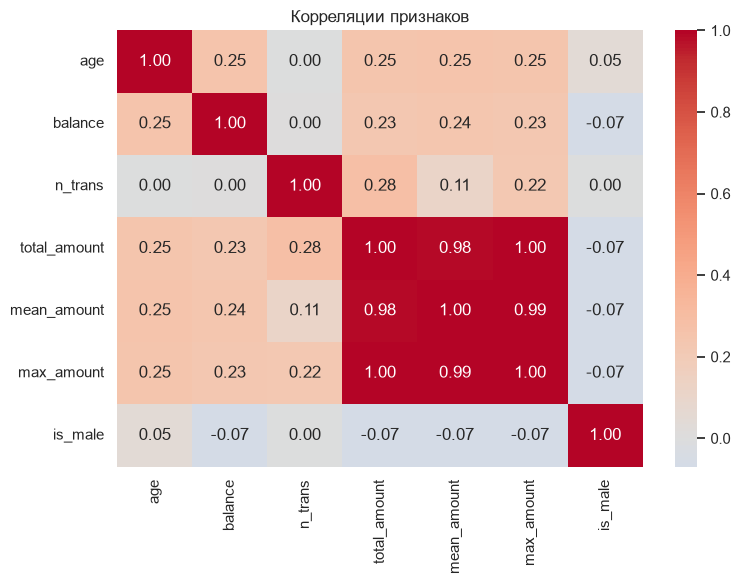

In [23]:
feats = num_cols + ["is_male"]
plt.figure(figsize=(8, 6))
sns.heatmap(X_df[feats].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляции признаков")
save("03_corr")

### Что получилось
На тепловой карте видны блоки сильно коррелированных признаков: `total_amount`, `mean_amount` и `max_amount` связаны между собой (особенно когда у клиента одна транзакция, эти значения почти совпадают). `age` и `is_male` слабо связаны с остальными, то есть несут независимую информацию.

✏️ **Впишите свои числа и вывод:** _..._

### Что делает ячейка
Удаляет признаки с |r| > 0.9 (оставляя более «чистые» `mean_amount` и `n_trans`), затем применяет **`StandardScaler`**: каждый признак приводится к среднему 0 и дисперсии 1. Проверяется дисперсия и отсутствие признаков-констант.

In [24]:
# total_amount и mean_amount/max_amount сильно коррелируют -> убираем дубли
corr = X_df[feats].corr().abs()
drop = [c for c in ["total_amount", "max_amount"] if corr.loc[c].drop(c).max() > 0.9]
feats = [c for c in feats if c not in drop]
print("\nУдалены из-за мультиколлинеарности:", drop)
print("Итоговые признаки:", feats)

scaler = StandardScaler()
X = scaler.fit_transform(X_df[feats])
print("Дисперсии после масштабирования:", X.var(axis=0).round(2))
print("Признаки с нулевой дисперсией:",
      [f for f, k in zip(feats, VarianceThreshold(1e-8).fit(X).get_support()) if not k])


Удалены из-за мультиколлинеарности: ['total_amount', 'max_amount']
Итоговые признаки: ['age', 'balance', 'n_trans', 'mean_amount', 'is_male']
Дисперсии после масштабирования: [1. 1. 1. 1. 1.]
Признаки с нулевой дисперсией: []


### Что получилось
Выведены: список удалённых признаков, итоговый набор признаков, дисперсии после масштабирования (все равны 1) и список признаков с нулевой дисперсией (пустой список означает, что все признаки информативны).

✏️ **Впишите свои числа и вывод:** _..._

### Что делает ячейка
Проверяет **условие применимости кластеризации**: считает **статистику Хопкинса**. Сравниваются расстояния до ближайших соседей у реальных точек и у случайных точек, равномерно распределённых в том же пространстве. Значение около 0.5 означает равномерные (случайные) данные, около 1 — выраженную кластерную структуру.

In [25]:
def hopkins(X, m=500, seed=RS):
    """Статистика Хопкинса: >0.7 - данные склонны к кластеризации."""
    rng = np.random.default_rng(seed)
    n, d = X.shape
    m = min(m, n // 2)
    nn = NearestNeighbors(n_neighbors=2).fit(X)
    idx = rng.choice(n, m, replace=False)
    w = nn.kneighbors(X[idx], 2)[0][:, 1].sum()
    U = rng.uniform(X.min(0), X.max(0), (m, d))
    u = nn.kneighbors(U, 1)[0][:, 0].sum()
    return u / (u + w)

H = hopkins(X)
print(f"Статистика Хопкинса: {H:.3f}")

Статистика Хопкинса: 0.972


### Что получилось
Выведено значение статистики Хопкинса. Интерпретация: **> 0.7** — данные склонны к кластеризации; **0.5–0.7** — структура слабая, кластеры будут скорее условными сегментами, чем естественными группами; **≈ 0.5** — кластеризация неосмысленна. В выводах отразите, к какому диапазону относится ваше значение.

✏️ **Впишите свои числа и вывод:** _..._

### Что делает ячейка
Берёт случайную подвыборку из 5000 клиентов (для силуэта и иерархической кластеризации нужна матрица расстояний, на всём датасете она не поместится в память) и строит **матрицу диаграмм рассеивания** на 1500 точках, чтобы визуально оценить структуру, число кластеров и их форму.

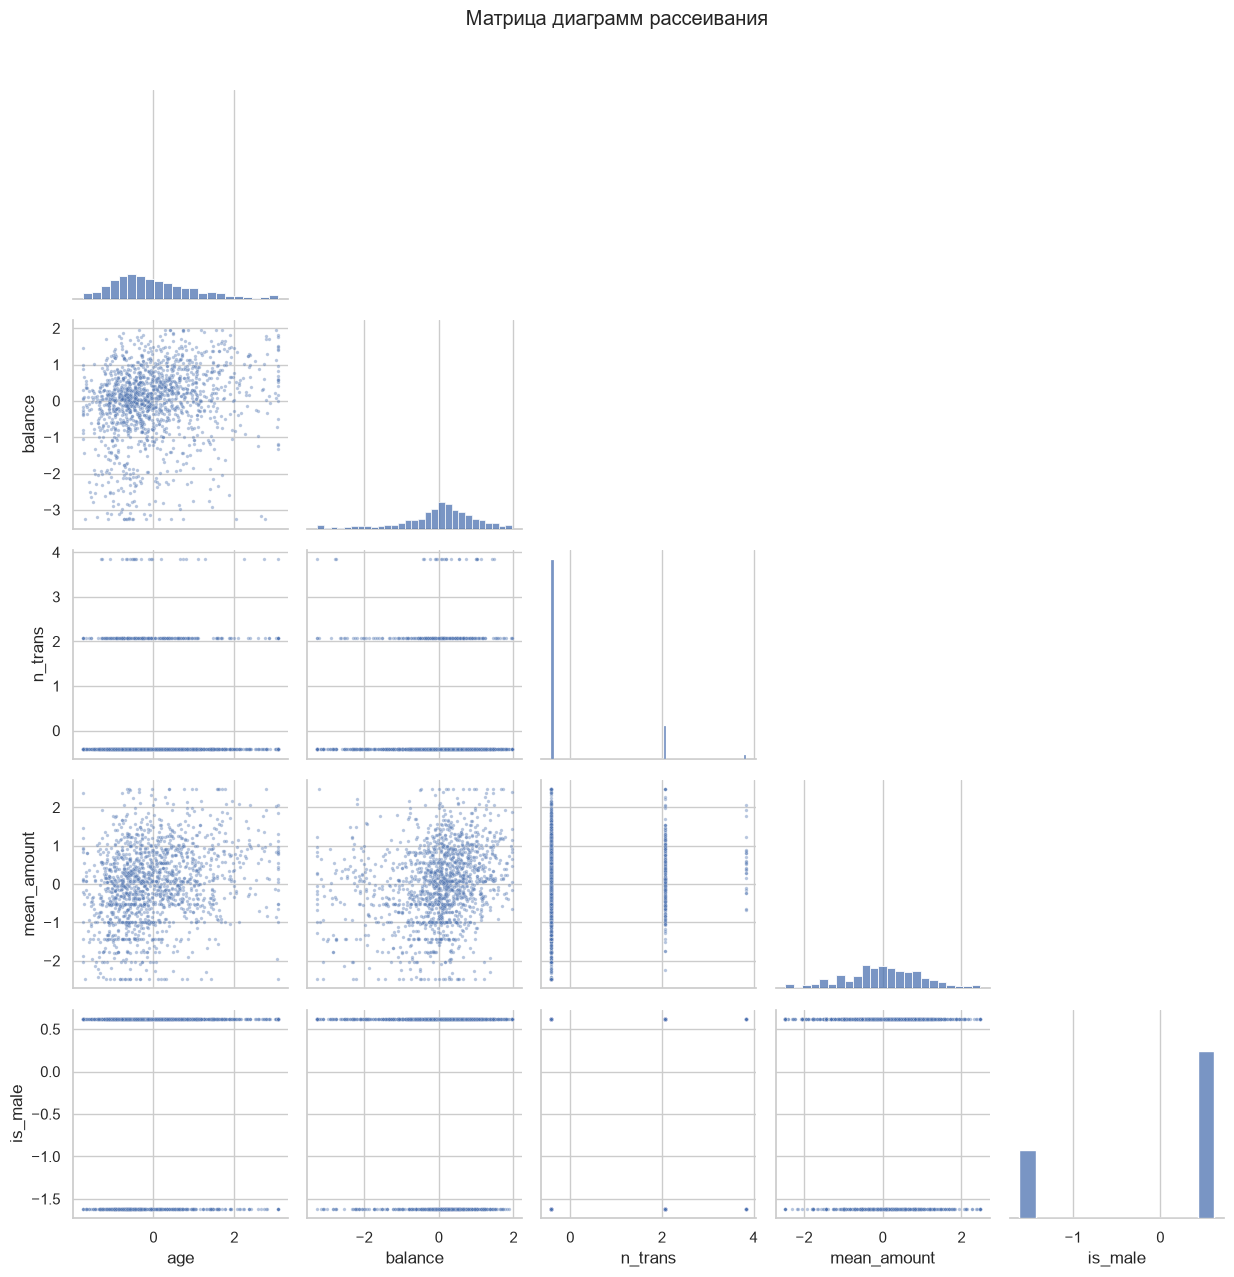

In [26]:
# Выборка для тяжёлых операций (силуэт, иерархия, pairplot)
N = min(5000, len(X))
sel = np.random.default_rng(RS).choice(len(X), N, replace=False)
Xs = X[sel]
Xs_df = pd.DataFrame(Xs, columns=feats)

sns.pairplot(Xs_df.sample(min(1500, N), random_state=RS), corner=True,
             plot_kws={"s": 6, "alpha": .4}, diag_kind="hist")
plt.suptitle("Матрица диаграмм рассеивания", y=1.02)
save("04_pairplot")

### Что получилось
На диаграммах нужно искать изолированные скопления, форму (сферическая или вытянутая) и неравномерность плотности. Типичная картина для таких данных: непрерывное «облако» без чётких границ, а `is_male` и `n_trans` дают дискретные полосы. Из этого следует аргументация выбора методов: **K-means** подходит для компактных кластеров примерно сферической формы, **Ward** тоже строит компактные кластеры и позволяет оценить структуру по дендрограмме, а **DBSCAN** был бы плохим выбором из-за разной плотности и отсутствия чётких границ.

✏️ **Впишите свои числа и вывод:** _..._

## 6. Подбор числа кластеров k

### Что делает ячейка
Для k от 2 до 10 обучает K-means и Ward и считает: **inertia** (сумма квадратов расстояний до центров, для метода локтя), **коэффициент силуэта** (чем выше, тем лучше), **индекс Калински-Харабаса** (чем выше, тем лучше) и **индекс Дэвиса-Болдина** (чем ниже, тем лучше). Строит три графика.


     k      inertia  km_sil     km_ch  km_db  hc_sil     hc_ch  hc_db
0   2  3341201.287   0.267  1224.975  1.617   0.317  1211.654  1.387
1   3  2665454.181   0.308  1412.424  1.341   0.291  1329.046  1.349
2   4  2149830.292   0.274  1560.092  1.220   0.252  1417.138  1.316
3   5  1890832.348   0.279  1501.302  1.155   0.252  1350.010  1.216
4   6  1701267.303   0.254  1441.396  1.150   0.214  1223.113  1.250
5   7  1566358.977   0.250  1361.050  1.184   0.229  1156.046  1.320
6   8  1442784.687   0.264  1325.104  1.250   0.206  1099.696  1.320
7   9  1362826.062   0.254  1268.000  1.244   0.194  1060.294  1.292
8  10  1285308.292   0.242  1214.252  1.234   0.193  1040.298  1.282


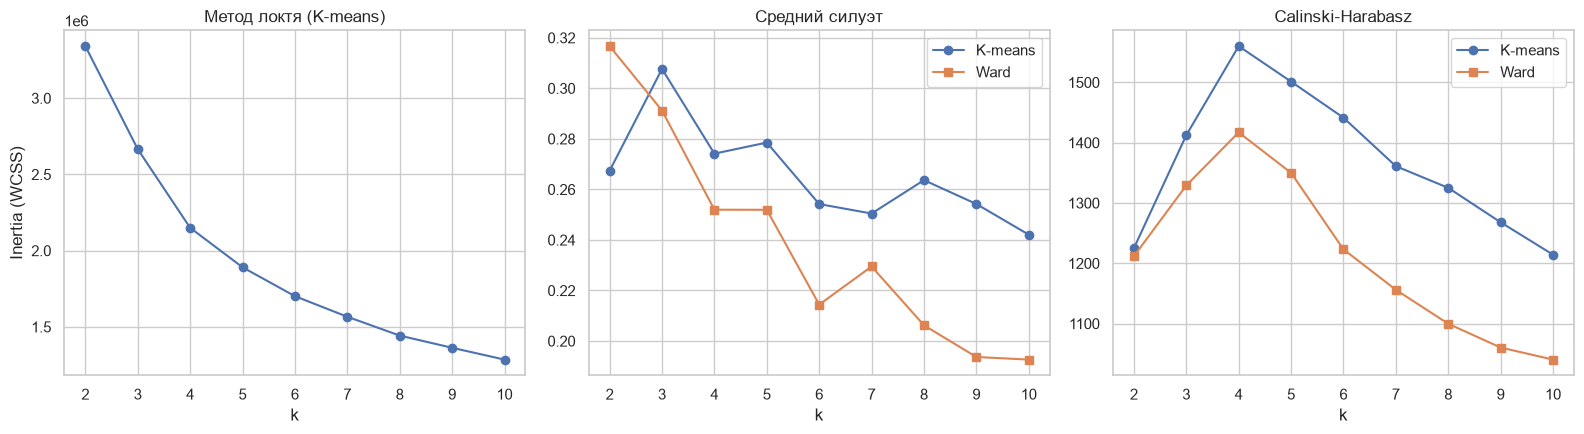

In [27]:
Ks = range(2, 11)
res = []
for k in Ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RS).fit(X)
    lab_s = km.predict(Xs)
    ag = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Xs)
    res.append(dict(k=k, inertia=km.inertia_,
                    km_sil=silhouette_score(Xs, lab_s),
                    km_ch=calinski_harabasz_score(Xs, lab_s),
                    km_db=davies_bouldin_score(Xs, lab_s),
                    hc_sil=silhouette_score(Xs, ag),
                    hc_ch=calinski_harabasz_score(Xs, ag),
                    hc_db=davies_bouldin_score(Xs, ag)))
sel_df = pd.DataFrame(res)
print("\n", sel_df.round(3))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
ax[0].plot(sel_df.k, sel_df.inertia, "o-"); ax[0].set_title("Метод локтя (K-means)")
ax[0].set_xlabel("k"); ax[0].set_ylabel("Inertia (WCSS)")
ax[1].plot(sel_df.k, sel_df.km_sil, "o-", label="K-means")
ax[1].plot(sel_df.k, sel_df.hc_sil, "s-", label="Ward"); ax[1].legend()
ax[1].set_title("Средний силуэт"); ax[1].set_xlabel("k")
ax[2].plot(sel_df.k, sel_df.km_ch, "o-", label="K-means")
ax[2].plot(sel_df.k, sel_df.hc_ch, "s-", label="Ward"); ax[2].legend()
ax[2].set_title("Calinski-Harabasz"); ax[2].set_xlabel("k")
save("05_k_selection")

### Что получилось
В консоли выведена таблица метрик по k, на графиках: **локоть** (точка, после которой inertia падает медленнее), **силуэт** (пик указывает на лучшее k) и **CH**. Как правило, силуэт убывает с ростом k, а inertia монотонно падает, поэтому выбор k это компромисс. Запишите, при каких k наблюдаются локоть и максимум силуэта.

✏️ **Впишите свои числа и вывод:** _..._

### Что делает ячейка
Определяет «колено» кривой inertia объективно: ищется точка, наиболее удалённая от прямой, соединяющей первую и последнюю точки графика. Также определяется k с максимальным силуэтом.

In [28]:
# Автоматическая подсказка по "колену" (макс. расстояние до хорды)
y = sel_df.inertia.values
xk = np.arange(len(y))
p1, p2 = np.array([0, y[0]]), np.array([xk[-1], y[-1]])
d = [abs(np.linalg.det(np.array([p2 - p1, np.array([i, y[i]]) - p1]))) / np.linalg.norm(p2 - p1)
     for i in xk]
k_elbow = int(sel_df.k[int(np.argmax(d))])
k_sil = int(sel_df.k[sel_df.km_sil.idxmax()])
print(f"k по локтю = {k_elbow}, k по силуэту = {k_sil}")

k по локтю = 5, k по силуэту = 3


### Что получилось
Напечатаны `k по локтю` и `k по силуэту`. Если значения различаются, это нормально: метод локтя субъективен, а силуэт даёт более строгий критерий. Окончательный выбор делается с учётом интерпретируемости сегментов.

✏️ **Впишите свои числа и вывод:** _..._

### Что делает ячейка
Строит **дендрограмму** иерархической кластеризации методом Ward на 2000 объектах (показаны последние 30 объединений). Высота по вертикали — расстояние, на котором объединяются кластеры.

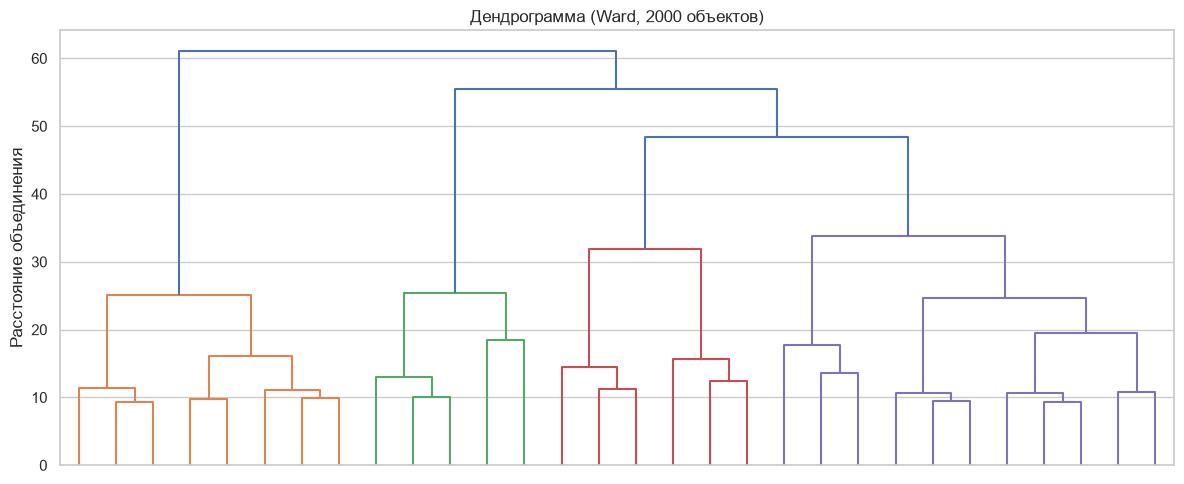

In [29]:
# Дендрограмма
Z = linkage(Xs[:2000], method="ward")
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True)
plt.title("Дендрограмма (Ward, 2000 объектов)")
plt.ylabel("Расстояние объединения")
save("06_dendrogram")

### Что получилось
Чтобы определить число кластеров, нужно «провести» горизонтальную линию через самые длинные вертикальные отрезки: число пересечённых ветвей равно рекомендуемому k. Сравните это число с k из локтя и силуэта: если они совпадают, выбор k обоснован сильнее.

✏️ **Впишите свои числа и вывод:** _..._

### Что делает ячейка
Фиксирует итоговое число кластеров `K`. По умолчанию берётся k по силуэту (но не меньше 3, так как два кластера для сегментации клиентов малоинформативны). **Это значение можно изменить вручную** по результатам предыдущих трёх графиков.

In [30]:
# >>> ВЫБЕРИТЕ ИТОГОВОЕ k ПО ГРАФИКАМ (компромисс силуэт / локоть / интерпретируемость)
K = k_sil if k_sil >= 3 else k_elbow
K = max(K, 3)  # для сегментации клиентов k=2 обычно неинформативно
print("Выбрано K =", K)

Выбрано K = 3


### Что получилось
Напечатано выбранное значение `K`. Обоснуйте выбор в отчёте: какие критерии (локоть, силуэт, дендрограмма) его поддержали и почему вы приняли именно такой компромисс.

✏️ **Впишите свои числа и вывод:** _..._

## 7. Итоговая кластеризация двумя методами

### Что делает ячейка
Обучает **K-means** (`n_init=10` — десять случайных инициализаций, берётся лучшая, чтобы избежать локальных минимумов) на всём датасете и **иерархическую кластеризацию Ward** на подвыборке из 5000 объектов. Для честного сравнения K-means также применяется к этой подвыборке (`lab_km`).

In [31]:
km = KMeans(n_clusters=K, n_init=10, random_state=RS).fit(X)
lab_km_full = km.labels_
lab_km = km.predict(Xs)
hc = AgglomerativeClustering(n_clusters=K, linkage="ward")
lab_hc = hc.fit_predict(Xs)

### Что получилось
Вывода нет. Созданы метки кластеров: `lab_km_full` (K-means, все клиенты), `lab_km` (K-means, выборка) и `lab_hc` (Ward, выборка). Дальше сравнение методов идёт на одних и тех же 5000 объектах.

## 8. Метрики качества

### Что делает ячейка
Для каждого метода считает **внутренние метрики**: силуэт, Calinski-Harabasz, Davies-Bouldin, а также **компактность** (среднее расстояние до центра), **внутрикластерное расстояние** (среднее попарное), **расстояния между центрами** и их отношение к компактности («между/внутри»; чем больше, тем лучше разделены кластеры). Выводятся матрицы расстояний между центрами, размеры кластеров и сравнительная таблица.

In [32]:
def cluster_stats(Xd, lab):
    ks = np.unique(lab)
    cents = np.array([Xd[lab == k].mean(0) for k in ks])
    # компактность: среднее расстояние до центра
    compact = [np.linalg.norm(Xd[lab == k] - cents[i], axis=1).mean()
               for i, k in enumerate(ks)]
    # средний попарный внутрикластерный диаметр (на подвыборке)
    diam = []
    for k in ks:
        pts = Xd[lab == k]
        pts = pts[:600]
        diam.append(pdist(pts).mean() if len(pts) > 1 else 0)
    cd = squareform(pdist(cents))
    min_between = cd[np.triu_indices(len(ks), 1)].min()
    return cents, np.array(compact), np.array(diam), cd, min_between

metrics = {}
for name, lab in [("K-means", lab_km), ("Hierarchical (Ward)", lab_hc)]:
    cents, comp, diam, cd, mb = cluster_stats(Xs, lab)
    metrics[name] = {
        "Silhouette": silhouette_score(Xs, lab),
        "Calinski-Harabasz": calinski_harabasz_score(Xs, lab),
        "Davies-Bouldin": davies_bouldin_score(Xs, lab),
        "Ср. компактность (расст. до центра)": comp.mean(),
        "Ср. внутрикл. расстояние": diam.mean(),
        "Мин. расст. между центрами": mb,
        "Ср. расст. между центрами": cd[np.triu_indices(K, 1)].mean(),
        "Отношение между/внутри": cd[np.triu_indices(K, 1)].mean() / comp.mean(),
    }
    print(f"\n{name}: расстояния между центрами\n", np.round(cd, 2))
    print("Размеры кластеров:", np.bincount(lab))


K-means: расстояния между центрами
 [[0.   2.79 2.25]
 [2.79 0.   3.18]
 [2.25 3.18 0.  ]]
Размеры кластеров: [3056  795 1149]

Hierarchical (Ward): расстояния между центрами
 [[0.   2.78 2.21]
 [2.78 0.   3.19]
 [2.21 3.19 0.  ]]
Размеры кластеров: [3149  795 1056]


### Что получилось
Получена сравнительная таблица двух методов (сохранена в `metrics_comparison.csv`). Ориентиры для интерпретации: силуэт > 0.5 — чёткая структура, 0.25–0.5 — умеренная, < 0.25 — слабая; чем **больше** CH и отношение «между/внутри», тем лучше; чем **меньше** DB, тем лучше. Посмотрите также на размеры кластеров: сильный дисбаланс (один гигантский и несколько маленьких кластеров) указывает на непрерывную структуру.

✏️ **Впишите свои числа и вывод:** _..._

### Что делает ячейка
Истинных меток классов в данных нет, поэтому внешние метрики используются как мера **согласованности двух методов**: Adjusted Rand Index, индекс Rand, Fowlkes-Mallows и индекс Жаккара (по парам объектов).

In [33]:
# Внешние метрики: согласованность двух методов (истинных классов нет)
ext = {"Adjusted Rand": adjusted_rand_score(lab_km, lab_hc),
       "Rand": rand_score(lab_km, lab_hc),
       "Fowlkes-Mallows": fowlkes_mallows_score(lab_km, lab_hc)}
# Индекс Жаккара по парам объектов
cm = confusion_matrix(lab_km, lab_hc)
n11 = (cm * (cm - 1) / 2).sum()
a = (cm.sum(1) * (cm.sum(1) - 1) / 2).sum()
b = (cm.sum(0) * (cm.sum(0) - 1) / 2).sum()
ext["Jaccard (по парам)"] = n11 / (a + b - n11)

table = pd.DataFrame(metrics).T
print("\n=== Сравнительная таблица ===\n", table.round(3))
print("\n=== Согласованность K-means и Ward ===\n", pd.Series(ext).round(3))
table.round(4).to_csv("metrics_comparison.csv")


=== Сравнительная таблица ===
                      Silhouette  Calinski-Harabasz  Davies-Bouldin  \
K-means                   0.308           1412.424           1.341   
Hierarchical (Ward)       0.291           1329.046           1.349   

                     Ср. компактность (расст. до центра)  \
K-means                                            1.672   
Hierarchical (Ward)                                1.654   

                     Ср. внутрикл. расстояние  Мин. расст. между центрами  \
K-means                                 2.364                       2.250   
Hierarchical (Ward)                     2.334                       2.213   

                     Ср. расст. между центрами  Отношение между/внутри  
K-means                                  2.742                    1.64  
Hierarchical (Ward)                      2.728                    1.65  

=== Согласованность K-means и Ward ===
 Adjusted Rand         0.938
Rand                  0.969
Fowlkes-Mallows       0.967


### Что получилось
Выведены четыре значения. **ARI ≈ 1** означает, что методы нашли почти одинаковое разбиение; **0.5–0.8** — умеренное согласие; **< 0.3** — методы выявили разные структуры. Высокое согласие означает, что кластеры не зависят от конкретного алгоритма.

✏️ **Впишите свои числа и вывод:** _..._

### Что делает ячейка
Строит **силуэтные диаграммы** для обоих методов: у каждого кластера показаны значения силуэта всех его объектов (красная линия — среднее).

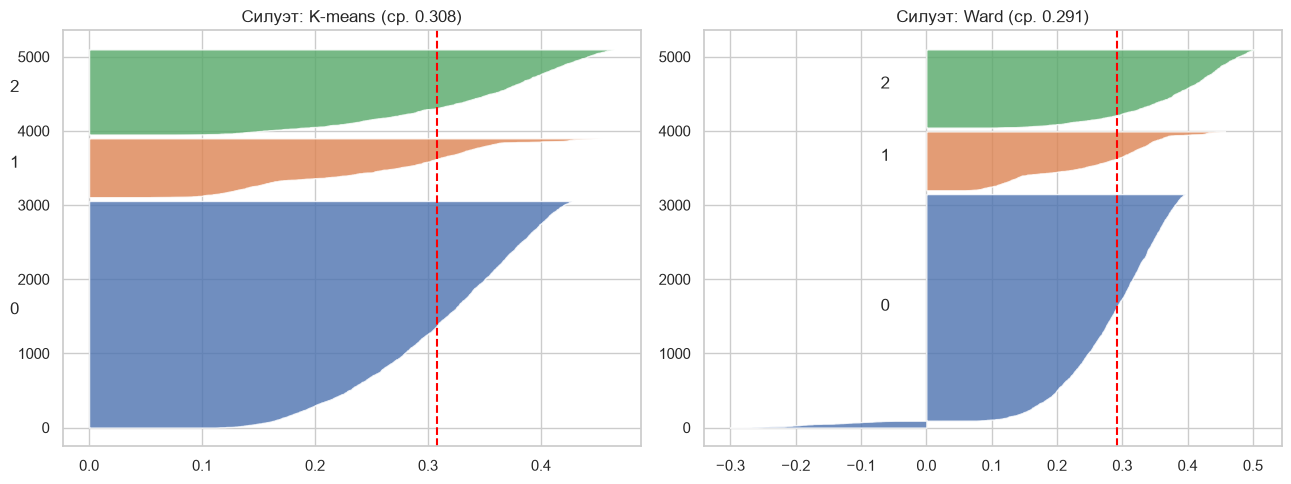

In [34]:
# Силуэт по кластерам
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a_, (name, lab) in zip(ax, [("K-means", lab_km), ("Ward", lab_hc)]):
    sv = silhouette_samples(Xs, lab)
    y0 = 0
    for k in range(K):
        v = np.sort(sv[lab == k])
        a_.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, alpha=.8)
        a_.text(-0.07, y0 + len(v) / 2, str(k))
        y0 += len(v) + 50
    a_.axvline(sv.mean(), color="red", ls="--")
    a_.set_title(f"Силуэт: {name} (ср. {sv.mean():.3f})")
save("07_silhouette_plot")

### Что получилось
Чем шире и длиннее «нож» кластера, тем лучше он выделен. Объекты с **отрицательным** силуэтом находятся, вероятно, не в «своём» кластере. Обратите внимание, какие кластеры выше среднего, а какие ниже.

✏️ **Впишите свои числа и вывод:** _..._

### Что делает ячейка
Оценивает **устойчивость K-means**: 20 раз берётся случайная подвыборка 80% данных, кластеризация повторяется, и результат сравнивается (через ARI) с основной моделью.

In [35]:
# Устойчивость K-means: бутстрэп ARI
aris = []
rng = np.random.default_rng(RS)
for i in range(20):
    idx = rng.choice(len(X), size=int(.8 * len(X)), replace=False)
    km_b = KMeans(n_clusters=K, n_init=10, random_state=i).fit(X[idx])
    aris.append(adjusted_rand_score(km.predict(X[idx]), km_b.labels_))
print(f"\nУстойчивость K-means (ARI по 20 подвыборкам): {np.mean(aris):.3f} ± {np.std(aris):.3f}")


Устойчивость K-means (ARI по 20 подвыборкам): 0.891 ± 0.258


### Что получилось
Напечатано среднее ARI ± стандартное отклонение. Ориентиры: **> 0.9** — очень устойчивое разбиение, **0.7–0.9** — приемлемо, **< 0.7** — кластеры нестабильны и сильно зависят от выборки.

✏️ **Впишите свои числа и вывод:** _..._

## 9. Влияние параметров на качество

### Что делает ячейка
Исследует влияние параметров K-means: **числа кластеров k** и **способа инициализации** (`k-means++` и `random`, при `n_init=1`, чтобы был виден эффект инициализации). Строятся графики силуэта, Davies-Bouldin и inertia.

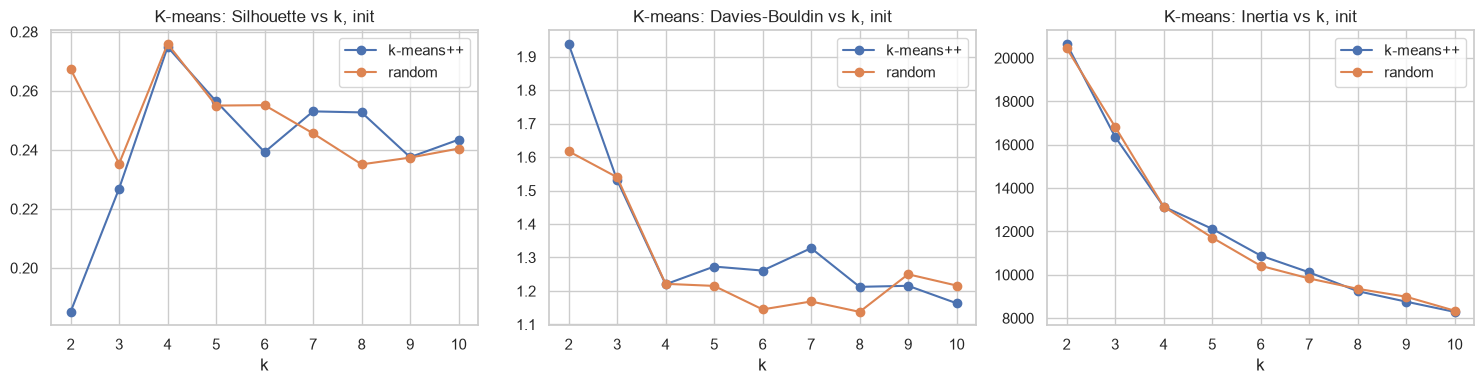

In [36]:
rows = []
for k in Ks:
    for init in ["k-means++", "random"]:
        m = KMeans(n_clusters=k, init=init, n_init=1, random_state=RS).fit(Xs)
        rows.append(dict(k=k, init=init, sil=silhouette_score(Xs, m.labels_),
                         db=davies_bouldin_score(Xs, m.labels_), inertia=m.inertia_))
p_df = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for init, s in p_df.groupby("init"):
    ax[0].plot(s.k, s.sil, "o-", label=init)
    ax[1].plot(s.k, s.db, "o-", label=init)
    ax[2].plot(s.k, s.inertia, "o-", label=init)
for a_, t in zip(ax, ["Silhouette", "Davies-Bouldin", "Inertia"]):
    a_.set_title(f"K-means: {t} vs k, init"); a_.set_xlabel("k"); a_.legend()
save("08_param_kmeans")

### Что получилось
По графикам видно, как меняется качество при росте k: inertia всегда убывает, а силуэт обычно снижается, поэтому оптимум не очевиден. Сравните `k-means++` и `random`: первый, как правило, стабильнее и даёт лучшую (меньшую) inertia.

✏️ **Впишите свои числа и вывод:** _..._

### Что делает ячейка
Проверяет влияние параметра `linkage` иерархической кластеризации (`ward`, `complete`, `average`, `single`) при выбранном `K`: считаются силуэт, CH и размер самого маленького кластера.

In [37]:
link_rows = []
for lk in ["ward", "complete", "average", "single"]:
    l = AgglomerativeClustering(n_clusters=K, linkage=lk).fit_predict(Xs)
    link_rows.append(dict(linkage=lk, sil=silhouette_score(Xs, l),
                          ch=calinski_harabasz_score(Xs, l),
                          min_cluster=np.bincount(l).min()))
print("\nВлияние linkage при k =", K, "\n", pd.DataFrame(link_rows).round(3))


Влияние linkage при k = 3 
     linkage    sil        ch  min_cluster
0      ward  0.291  1329.046          795
1  complete  0.230   992.970          704
2   average  0.292    11.035            3
3    single  0.273   729.939          212


### Что получилось
Выведена таблица. Обычно `ward` даёт лучший силуэт и сбалансированные кластеры, а `single` страдает от «эффекта цепочки»: один огромный кластер и мелкие группы из нескольких объектов (это видно по `min_cluster`). Это обоснование выбора Ward.

✏️ **Впишите свои числа и вывод:** _..._

## 10. Визуализация в пространстве главных компонент

### Что делает ячейка
Снижает размерность до двух **главных компонент (PCA)** и рисует диаграммы рассеивания для K-means (с центрами) и Ward в одинаковых осях.

Объяснённая дисперсия PCA: [0.303 0.206]


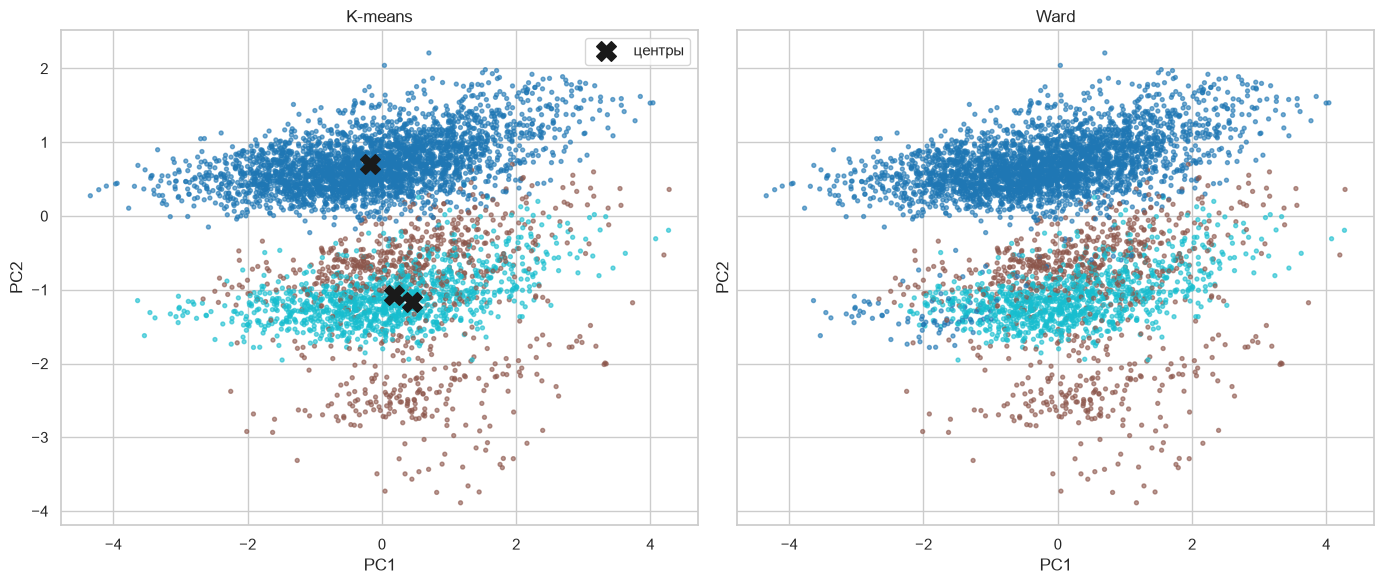

In [38]:
pca = PCA(n_components=2, random_state=RS).fit(X)
P = pca.transform(Xs)
print("Объяснённая дисперсия PCA:", pca.explained_variance_ratio_.round(3))
fig, ax = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for a_, (t, lab) in zip(ax, [("K-means", lab_km), ("Ward", lab_hc)]):
    sc = a_.scatter(P[:, 0], P[:, 1], c=lab, cmap="tab10", s=8, alpha=.6)
    a_.set_title(t); a_.set_xlabel("PC1"); a_.set_ylabel("PC2")
cp = pca.transform(km.cluster_centers_)
ax[0].scatter(cp[:, 0], cp[:, 1], c="k", marker="X", s=200, label="центры")
ax[0].legend()
save("09_pca_clusters")

### Что получилось
Выведена доля дисперсии, объяснённая двумя компонентами. Если она мала (< 60%), перекрытие кластеров на графике частично связано с потерей информации при проекции. Сравните два графика: насколько совпадают границы кластеров двух методов, что согласуется с ARI выше.

✏️ **Впишите свои числа и вывод:** _..._

## 11. Интерпретация кластеров

### Что делает ячейка
Возвращается к **исходным единицам** (годы, рупии, число транзакций) и считает профиль каждого кластера K-means: размер, средний возраст, доля мужчин, медианные баланс и суммы транзакций, среднее число транзакций, доля от всех клиентов. Профили сохраняются в `cluster_profiles.csv`.

In [39]:
prof = df.copy()
prof["cluster"] = lab_km_full
profile = prof.groupby("cluster").agg(
    size=("age", "size"), age=("age", "mean"), is_male=("is_male", "mean"),
    balance=("balance", "median"), n_trans=("n_trans", "mean"),
    mean_amount=("mean_amount", "median"), total_amount=("total_amount", "median"))
profile["share_%"] = 100 * profile["size"] / profile["size"].sum()
print("\n=== Профили кластеров K-means (исходные единицы) ===\n", profile.round(2))
profile.round(2).to_csv("cluster_profiles.csv")


=== Профили кластеров K-means (исходные единицы) ===
            size    age  is_male   balance  n_trans  mean_amount  total_amount  \
cluster                                                                         
0        512918  31.40     1.00  14618.83     1.00        399.0         399.0   
1        128479  31.23     0.72  16198.46     2.13        630.0        1338.0   
2        196396  30.70     0.00  20195.99     1.00        501.0         501.0   

         share_%  
cluster           
0          61.22  
1          15.34  
2          23.44  


### Что получилось
Таблица профилей. По ней каждому кластеру нужно дать **название и описание**, например: «молодые клиенты с небольшим балансом и малой активностью», «клиенты с высоким балансом и крупными транзакциями», «возрастные клиенты с редкими операциями». Для каждого сегмента можно указать маркетинговую рекомендацию.

✏️ **Впишите свои числа и вывод:** _..._

### Что делает ячейка
Строит **тепловую карту центров кластеров** в стандартизованных признаках: показывает, насколько каждый кластер отличается от среднего клиента по каждому признаку.

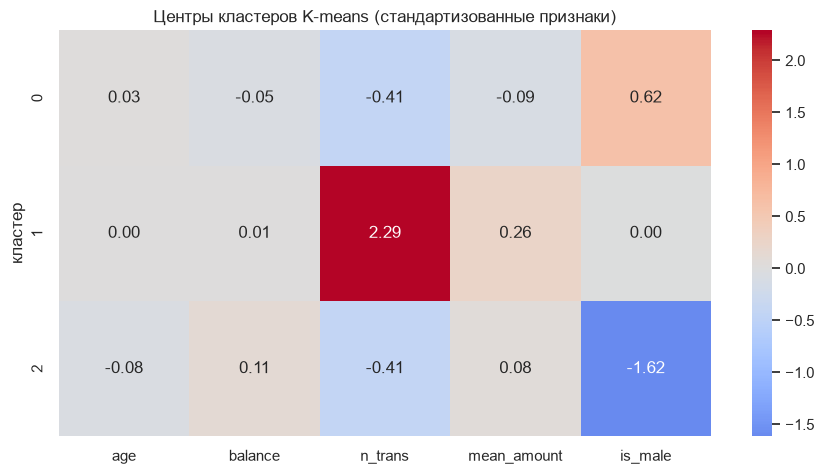


Готово: графики в папке figures


In [40]:
centers_std = pd.DataFrame(km.cluster_centers_, columns=feats)
plt.figure(figsize=(9, 4 + K * .3))
sns.heatmap(centers_std, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Центры кластеров K-means (стандартизованные признаки)")
plt.ylabel("кластер")
save("10_centers_heatmap")
print("\nГотово: графики в папке", OUT)

### Что получилось
**Красный** цвет — значение выше среднего по датасету, **синий** — ниже. По карте видно, какие признаки главным образом определяют каждый кластер. Используйте её вместе с таблицей профилей для финальной интерпретации.

✏️ **Впишите свои числа и вывод:** _..._

## Заключение

✏️ Заполните по итогам запуска:

1. **Данные:** размерность, признаки, что сделали с выбросами и скошенностью, значение статистики Хопкинса и вывод о применимости кластеризации.
2. **Выбор k:** что показали локоть, силуэт, дендрограмма, какое `K` выбрано и почему.
3. **Сравнение методов:** таблица метрик, какой метод лучше по силуэту, CH, DB, и согласованность (ARI).
4. **Устойчивость и параметры:** результат бутстрэпа, влияние k, инициализации и `linkage`.
5. **Интерпретация кластеров:** названия и описание сегментов клиентов.
6. **Применимость методов:** почему K-means и Ward подходят (или не подходят) для данного типа данных, ограничения (слабая кластерная структура, выборка 5000 объектов для Ward).